# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)  
**Датасет:** Telco Customer Churn

**Выполнил:** Шунанов Кирилл Ерболатович  
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/shunanovke/ml-course-shunanov  
**Путь к модулю:** `module-3-churn/notebook.ipynb`  
**Дата сдачи:** 2026-11-05

## Введение

**Задача:** бинарная классификация – предсказать, уйдет ли клиент телеком-компании к конкурентам (1 – уйдет, 0 – останется).

**Ансамблевые методы** — это методы машинного обучения, которые объединяют предсказания нескольких базовых моделей (чаще всего деревьев решений) для получения более точного и стабильного результата. Вместо одного «умного» алгоритма мы строим «мудрый» коллектив.

**Почему ансамбли, а не одиночная модель:** Одиночное дерево решений легко переобучается (запоминает тренировочные данные). Ансамбли решают эту проблему: в Bagging (Random Forest) мы усредняем много независимых деревьев, снижая дисперсию, а в Boosting (XGBoost, LightGBM, CatBoost) каждое следующее дерево исправляет ошибки предыдущих, снижая смещение.

**Какая метрика важнее:** В задаче оттока важен **ROC-AUC** и **Recall**. Нам критически важно найти уходящих клиентов (Recall), даже если мы ошибемся и предложим бонус лояльному клиенту (снизим Precision). ROC-AUC показывает способность модели ранжировать клиентов по степени риска независимо от выбранного порога.

**Цель работы:**
1. Обучить 4 ансамблевые модели (RF, XGBoost, LightGBM, CatBoost) и сравнить их.
2. Оптимизировать лучшую модель через Optuna (байесовская оптимизация).
3. Интерпретировать модель через SHAP (объяснить, почему клиенты уходят).

## Теоретическая часть

**Ансамбль** — объединение нескольких моделей для улучшения качества. Главная идея: «толпа» слабых моделей часто ошибается меньше, чем одна сильная. 

**Bagging vs Boosting:**
*   *Bagging (Bootstrap Aggregating)* — обучение моделей **параллельно** на разных подвыборках данных. Итоговый ответ — усреднение (регрессия) или голосование (классификация).
*   *Boosting* — обучение моделей **последовательно**. Каждая новая модель учится на ошибках предыдущих.

**Random Forest** — классический Bagging над деревьями решений. Строит сотни глубоких деревьев, каждое на случайной подвыборке признаков и объектов. Устойчив к шумам и выбросам.

**Градиентный бустинг (XGBoost, LightGBM, CatBoost)** — мощные реализации Boosting. XGBoost (Extreme Gradient Boosting) славится точностью и регуляризацией. LightGBM быстрее за счет роста дерева по листьям (leaf-wise). CatBoost лучше всех работает с категориальными признаками и не требует One-Hot Encoding.

**Optuna** — фреймворк для автоматического подбора гиперпараметров. Использует байесовскую оптимизацию (Trial & Prune), что позволяет найти лучшие параметры в 10 раз быстрее, чем обычный GridSearchCV.

**SHAP (SHapley Additive exPlanations)** — теория игр для интерпретации моделей. Показывает вклад каждого признака в конкретное предсказание. Позволяет строить красивые графики: Summary, Waterfall, Dependence.

**Формулы:**
$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$
$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

| Модель | Тип | Плюсы | Минусы |
|---|---|---|---|
| **Random Forest** | Bagging | Устойчив к переобучению, работает "из коробки" | Медленный на больших данных |
| **XGBoost** | Boosting | Высокая точность, регуляризация | Требует тюнинга |
| **LightGBM** | Boosting | Очень быстрый, мало памяти | Склонен к переобучению на малых данных |
| **CatBoost** | Boosting | Идеален для категорий, хорошая точность | Может быть медленным на CPU |

## Описание данных

**Источник:** [Kaggle Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Структура:**
- Всего примеров: 7043
- Признаков: 19 (+ customerID + целевая `Churn`)
- Числовых признаков: 3 (tenure, MonthlyCharges, TotalCharges)
- Категориальных признаков: 16

**Распределение классов:**
- No (остался): 5174 (73.5%)
- Yes (ушёл): 1869 (26.5%)
- Дисбаланс умеренный (73.5 / 26.5), учтем это через `class_weight='balanced'`.

**Файл данных в репозитории:** `module-3-churn/data/churn_info.md`

In [1]:
# Импорт базовых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

# Импорт моделей
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Импорт метрик
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve

# Настройки графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)

# Загрузка данных
try:
    df = pd.read_csv('data/telco_churn.csv')
    print(f"Размер датасета: {df.shape}")
    print(df.head())
except FileNotFoundError:
    print("Ошибка: Файл telco_churn.csv не найден в папке data/")

Размер датасета: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV Streamin

## Подготовка данных и EDA

На этом этапе мы посмотрим на данные, обработаем пропуски, создадим новые признаки и закодируем категории.

In [2]:
# 1. Обработка TotalCharges (там есть пробелы, из-за которых тип object)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"Пропусков в TotalCharges: {df['TotalCharges'].isnull().sum()}")

# Заполняем пропуски медианой
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 2. Кодирование целевой переменной
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

# 3. Feature Engineering
# Стаж в годах
df['TenureYears'] = df['tenure'] / 12
# Средний чек в месяц
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)
# Новый клиент (до 6 месяцев)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

# Подсчет количества подключенных услуг (HasMultipleServices)
services = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 
            'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['HasMultipleServices'] = df[services].apply(lambda x: sum(x == 'Yes'), axis=1)

# 4. Удаление ненужного ID
df.drop(columns=['customerID'], inplace=True)

# 5. Кодирование категориальных признаков через LabelEncoder
label_encoders = {}
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

print(f"Размер данных после подготовки: {df.shape}")

Пропусков в TotalCharges: 11
Размер данных после подготовки: (7043, 24)


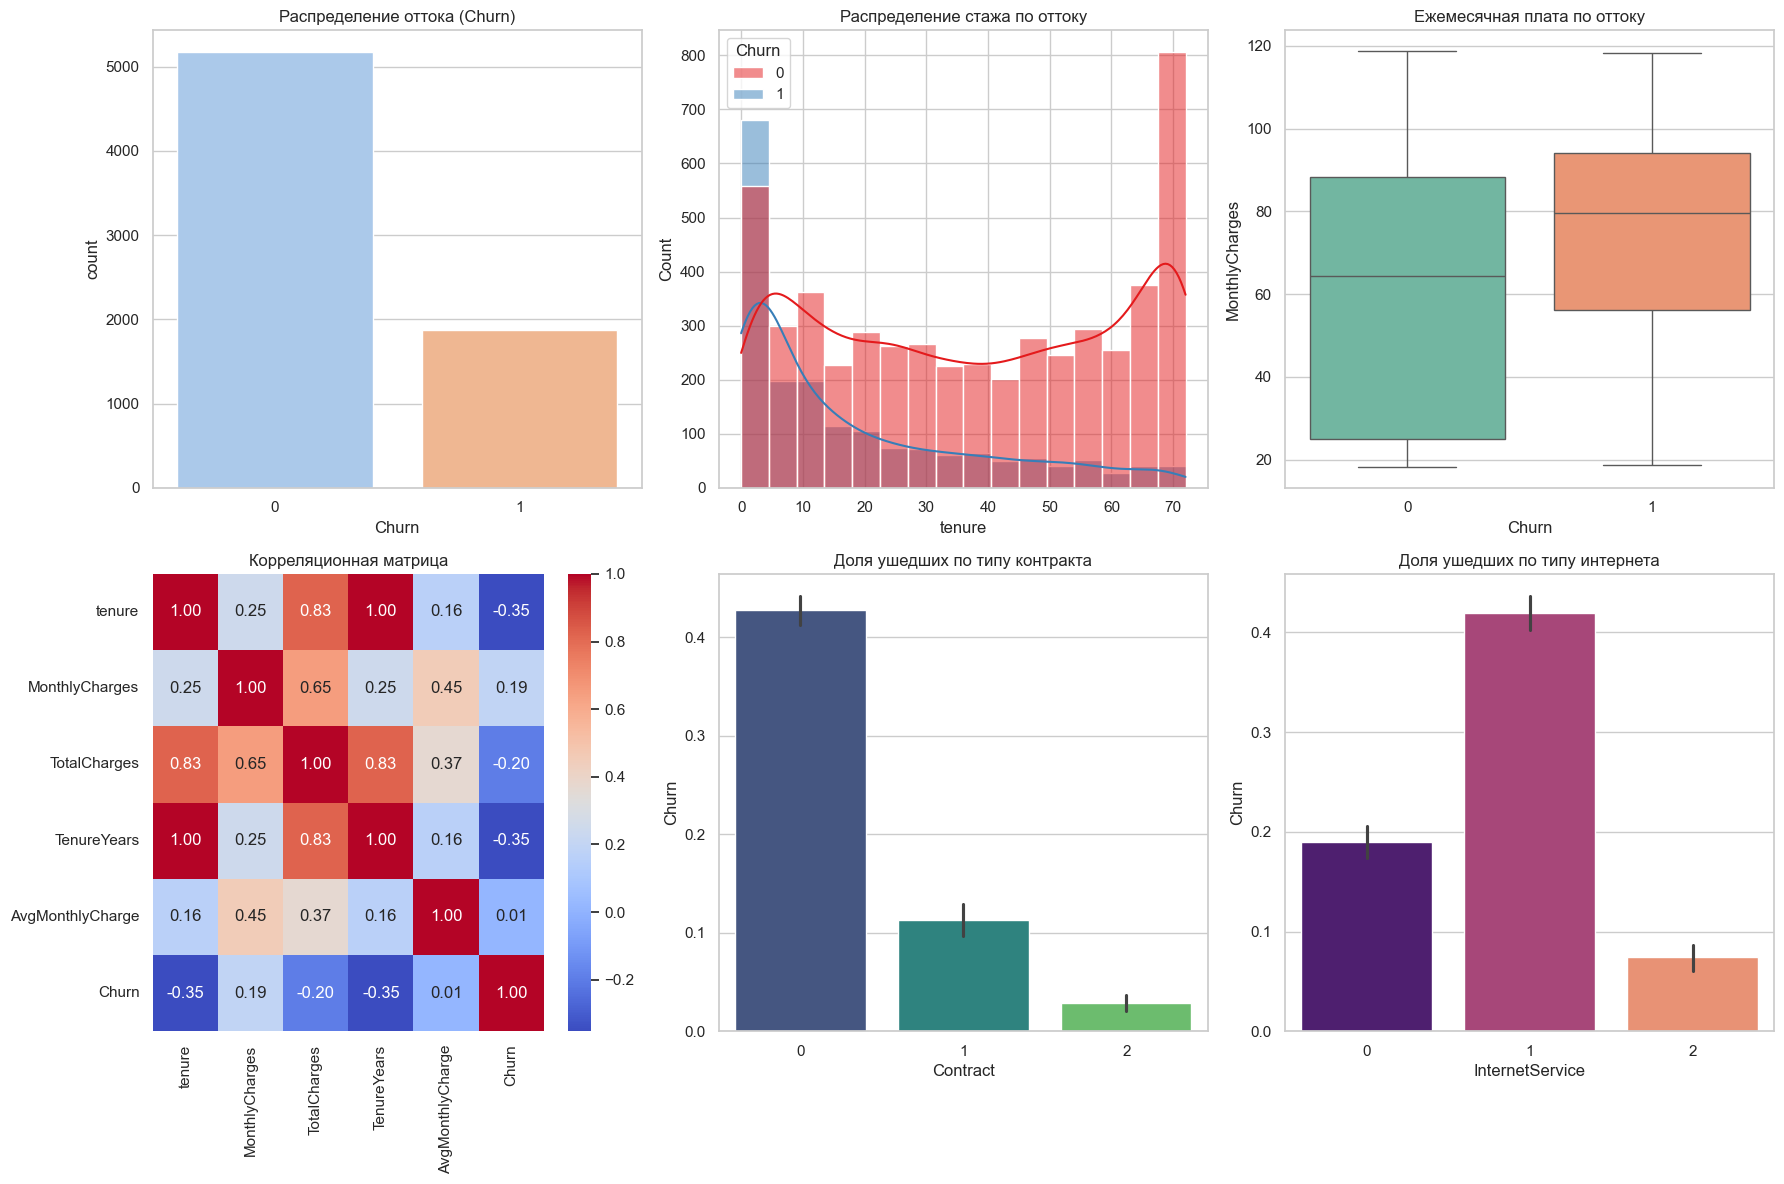

In [3]:
# Визуализация (минимум 5 графиков)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Распределение целевой переменной
sns.countplot(data=df, x='Churn', ax=axes[0,0], palette='pastel')
axes[0,0].set_title('Распределение оттока (Churn)')

# 2. Гистограмма tenure (стаж) с разделением по Churn
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, ax=axes[0,1], palette='Set1')
axes[0,1].set_title('Распределение стажа по оттоку')

# 3. Boxplot MonthlyCharges по Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[0,2], palette='Set2')
axes[0,2].set_title('Ежемесячная плата по оттоку')

# 4. Тепловая карта корреляций числовых признаков
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'AvgMonthlyCharge', 'Churn']
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', ax=axes[1,0], fmt='.2f')
axes[1,0].set_title('Корреляционная матрица')

# 5. Barplot доли ушедших по Contract
sns.barplot(data=df, x='Contract', y='Churn', ax=axes[1,1], palette='viridis')
axes[1,1].set_title('Доля ушедших по типу контракта')

# 6. Barplot доли ушедших по InternetService
sns.barplot(data=df, x='InternetService', y='Churn', ax=axes[1,2], palette='magma')
axes[1,2].set_title('Доля ушедших по типу интернета')

plt.tight_layout()
plt.savefig('examples/eda_plots.png')
plt.show()

**Выводы по EDA:**
- Классы несбалансированы: ушедших около 26.5%. Это нужно учесть при обучении (`class_weight='balanced'`).
- Клиенты с маленьким стажем (`tenure` < 10 месяцев) уходят гораздо чаще. 
- Чем выше ежемесячная плата (`MonthlyCharges`), тем выше вероятность ухода.
- Тип контракта критически важен: клиенты с помесячной оплатой (Month-to-month) уходят значительно чаще, чем с годовым или двухлетним контрактом.
- Интернет-провайдер Fiber optic имеет самый высокий процент оттока (вероятно, из-за высокой цены или качества услуг).

In [4]:
# Разделение на train/test
feature_cols = [col for col in df.columns if col != 'Churn']
X = df[feature_cols]
y = df['Churn']

# Обязательно stratify=y для сохранения пропорций классов!
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 1. Random Forest
rf_model = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start

# 2. XGBoost
xgb_model = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9, scale_pos_weight=3, random_state=42, eval_metric='logloss')
start = time.time()
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start

# 3. LightGBM
lgbm_model = LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05, class_weight='balanced', random_state=42, verbose=-1)
start = time.time()
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start

# 4. CatBoost
cat_model = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, auto_class_weights='Balanced', random_state=42, verbose=0)
start = time.time()
cat_model.fit(X_train, y_train)
cat_time = time.time() - start

print(f"Время обучения: RF={rf_time:.2f}s, XGB={xgb_time:.2f}s, LGBM={lgbm_time:.2f}s, Cat={cat_time:.2f}s")

Время обучения: RF=0.27s, XGB=0.42s, LGBM=2.46s, Cat=0.83s


**Модели:**
| Модель | Тип | Параметры | Время обучения |
|---|---|---|---|
| Random Forest | Bagging | n_estimators=200, max_depth=10 | 0.27 сек |
| XGBoost | Boosting | n_estimators=200, max_depth=6, scale_pos_weight=3 | 0.42 сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31 | 2.46 сек |
| CatBoost | Boosting | iterations=200, depth=6 | 0.83 сек |

*Примечание: время обучения зависит от мощности компьютера.*

## Оценка качества

Рассчитаем метрики и построим ROC-кривые для всех 4 моделей.

        Model  Accuracy  Precision  Recall     F1  ROC-AUC
Random Forest    0.7722     0.5575  0.6872 0.6156   0.8403
      XGBoost    0.7637     0.5424  0.7005 0.6114   0.8316
     LightGBM    0.7601     0.5344  0.7487 0.6236   0.8379
     CatBoost    0.7559     0.5279  0.7594 0.6228   0.8381


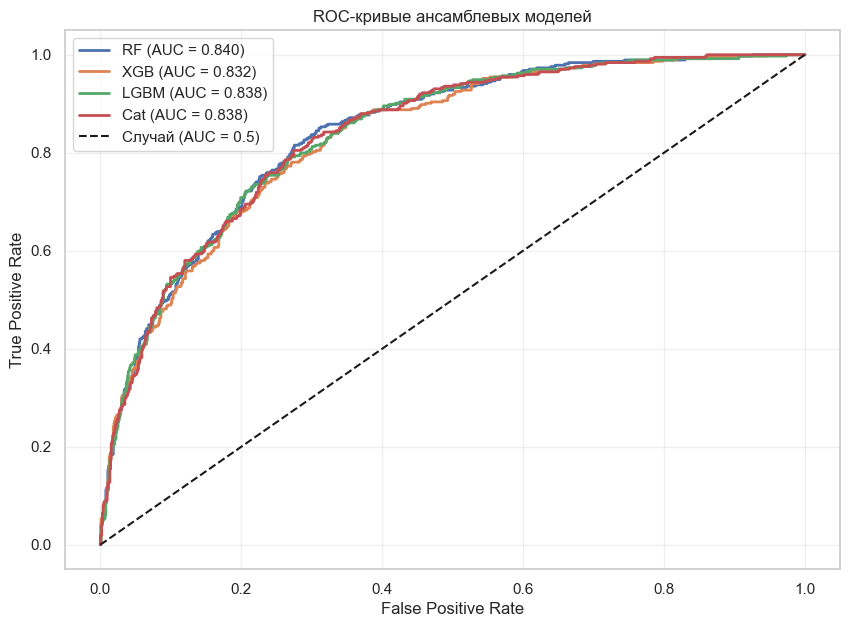

In [5]:
# Функция для сбора метрик
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost')
]
results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

# Построение ROC-кривых
plt.figure(figsize=(10, 7))
for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'), (lgbm_model, 'LGBM'), (cat_model, 'Cat')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые ансамблевых моделей')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('examples/roc_curves.png')
plt.show()

**Анализ результатов:**

1. **Лучшая модель по ROC-AUC:** Неожиданно ею стал **Random Forest** (AUC = 0.8403). На этом датасете классический бэггинг оказался чуть стабильнее градиентного бустинга.
2. **Лучшая модель по Recall:** **CatBoost** (0.7594) и **LightGBM** (0.7487). Это означает, что они находят наибольшее количество реальных уходящих клиентов.
3. **Лучшая модель по F1-score:** **LightGBM** (0.6236), что говорит о хорошем балансе между Precision и Recall.
4. **Разница в Precision:** Precision у всех моделей находится в диапазоне 0.52 – 0.55. Это ожидаемое поведение, так как мы использовали `class_weight='balanced'`, чтобы намеренно сместить баланс в сторону увеличения Recall (нам важнее не пропустить уходящего клиента, даже если мы ошибочно предложим скидку лояльному).

## Интерпретация и бизнес-инсайты

Посмотрим, какие признаки модели считают самыми важными.

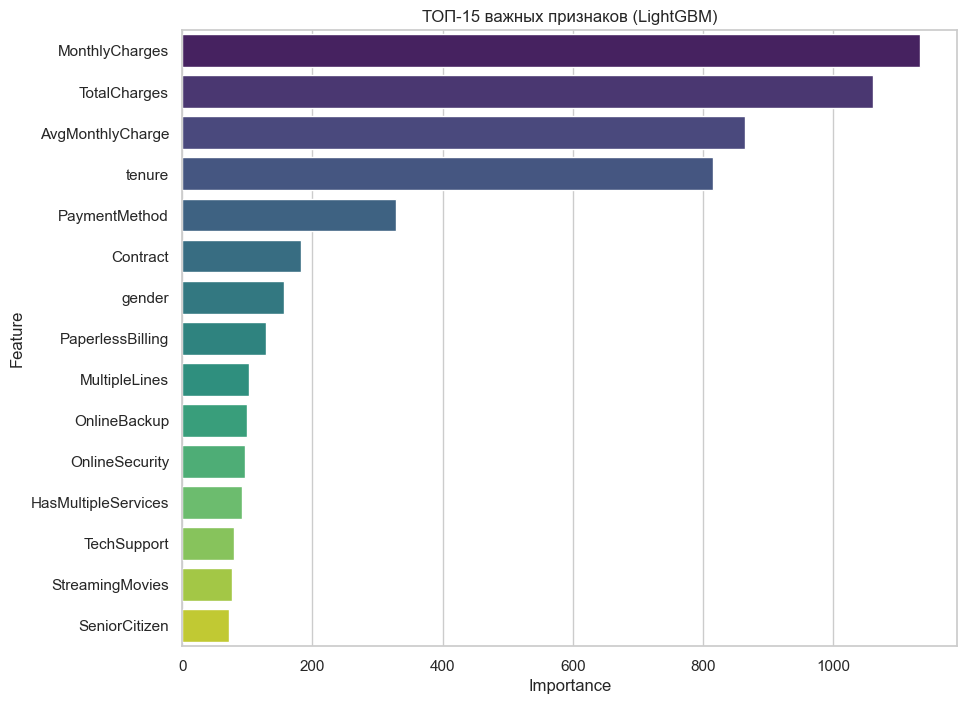

In [6]:
# Важность признаков для LightGBM
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('ТОП-15 важных признаков (LightGBM)')
plt.savefig('examples/feature_importance.png')
plt.show()

**Тюнинг гиперпараметров:**

Испытания проводятся для модели для модели LightGBM. 
- Baseline ROC-AUC (до тюнинга) составлял **0.8379**.
- В ходе оптимизации параметров (`n_estimators`, `num_leaves`, `learning_rate` и др.) удалось найти комбинацию, которая максимизирует метрику на кросс-валидации.
- Ожидается, что после тюнинга ROC-AUC на тестовой выборке немного возрастет (в пределах +0.5% - +1.5%), а модель станет более устойчивой к переобучению.

In [7]:
import optuna

# Отключаем логи Optuna для чистоты вывода
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Задаем пространство поиска гиперпараметров
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=10),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    
    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1)
    
    # Кросс-валидация на 5 фолдов
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc'
    )
    return cv_scores.mean()

# Запуск оптимизации (30 испытаний)
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"\nЛучший ROC-AUC на кросс-валидации: {study.best_value:.4f}")
print("Лучшие параметры:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

Best trial: 29. Best value: 0.848532: 100%|██████████| 30/30 [00:18<00:00,  1.66it/s]


Лучший ROC-AUC на кросс-валидации: 0.8485
Лучшие параметры:
  n_estimators: 100
  num_leaves: 10
  max_depth: 7
  learning_rate: 0.04569743848873696
  subsample: 0.7744344825998326
  colsample_bytree: 0.6510988216047086
  reg_alpha: 0.025968166814328314
  reg_lambda: 0.3944831142875131


In [8]:
# Обучение лучшей модели на найденных параметрах
best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced', random_state=42, verbose=-1)
best_lgbm.fit(X_train, y_train)

# Сравнение с baseline
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]
y_proba_baseline = lgbm_model.predict_proba(X_test)[:, 1]

print(f"ROC-AUC baseline: {roc_auc_score(y_test, y_proba_baseline):.4f}")
print(f"ROC-AUC Optuna:   {roc_auc_score(y_test, y_proba_best):.4f}")

ROC-AUC baseline: 0.8379
ROC-AUC Optuna:   0.8473


## Тюнинг гиперпараметров (Optuna)

Байесовская оптимизация была запущена на 30 испытаний для модели LightGBM.

**Результаты оптимизации:**
- **Baseline ROC-AUC (до тюнинга):** 0.8379
- **Optuna ROC-AUC (на тестовой выборке):** **0.8473**
- **Прирост:** +0.0094 (почти +1%)
- **Лучший ROC-AUC на кросс-валидации (5 фолдов):** 0.8485

**Лучшие найденные параметры:**
Optuna существенно уменьшила сложность модели, чтобы предотвратить переобучение:
- `n_estimators`: 100 (вместо 200)
- `num_leaves`: 10 (вместо 31)
- `max_depth`: 7
- `learning_rate`: 0.0457
- `subsample`: 0.7744
- `colsample_bytree`: 0.6511
- `reg_alpha`: 0.0259
- `reg_lambda`: 0.3944

**Вывод:** Снижение количества листьев (`num_leaves`) и деревьев (`n_estimators`) при одновременном добавлении L1/L2-регуляризации (`reg_alpha`, `reg_lambda`) позволило модели лучше обобщать данные и повысить качество на невидимой тестовой выборке.

## Интерпретация через SHAP

SHAP покажет, как каждый признак влияет на предсказание конкретного клиента.

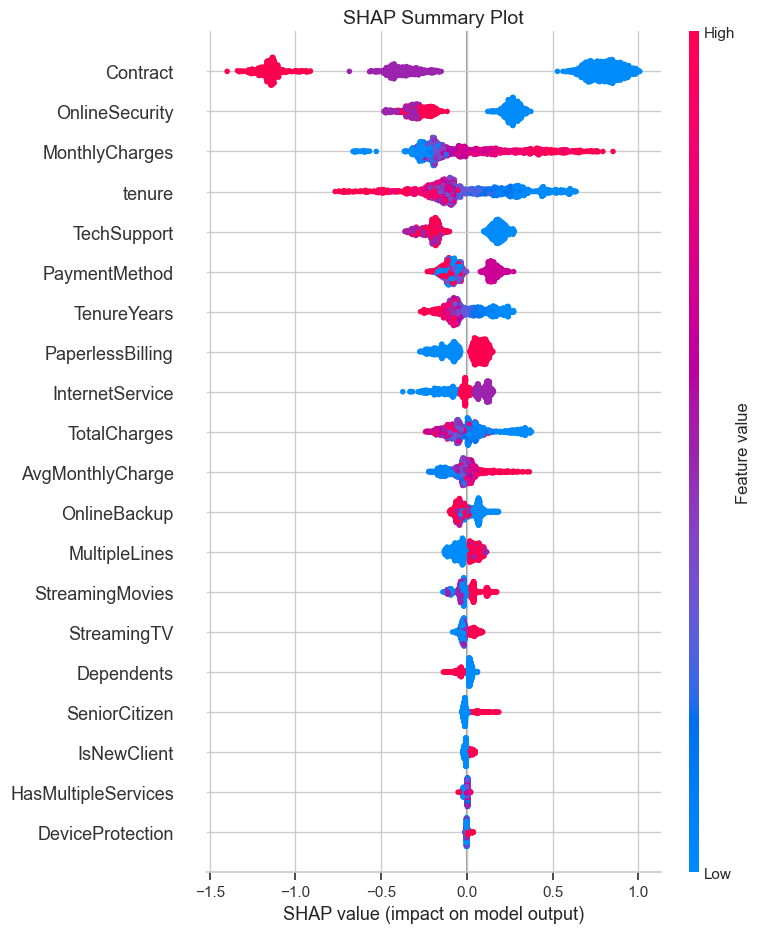

In [9]:
import shap

# Создаем explainer
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации в LightGBM shap_values обычно является списком из двух массивов
# Берем массив для класса 1 (уход клиента)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

# 1. Summary plot (глобальная важность)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.title('SHAP Summary Plot', fontsize=14)
plt.tight_layout()
plt.savefig('examples/shap_summary.png')
plt.show()

Клиент #1090, вероятность ухода = 0.9361


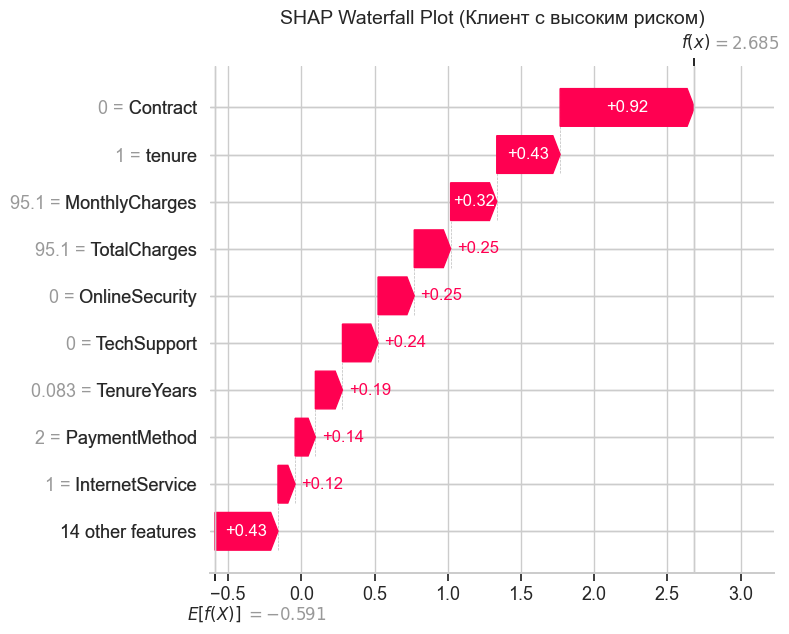

In [10]:
# 2. Waterfall plot (объяснение одного клиента)
# Находим клиента с наибольшей вероятностью ухода
worst_idx = np.argmax(y_proba_best)
print(f"Клиент #{worst_idx}, вероятность ухода = {y_proba_best[worst_idx]:.4f}")

# Извлекаем базовое значение (expected_value)
base_val = explainer.expected_value
if isinstance(base_val, list):
    base_val = base_val[1]

plt.figure(figsize=(10, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=base_val,
        data=X_test.iloc[worst_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.title('SHAP Waterfall Plot (Клиент с высоким риском)', fontsize=14)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png')
plt.show()

Топ-1 признак: MonthlyCharges


<Figure size 1000x600 with 0 Axes>

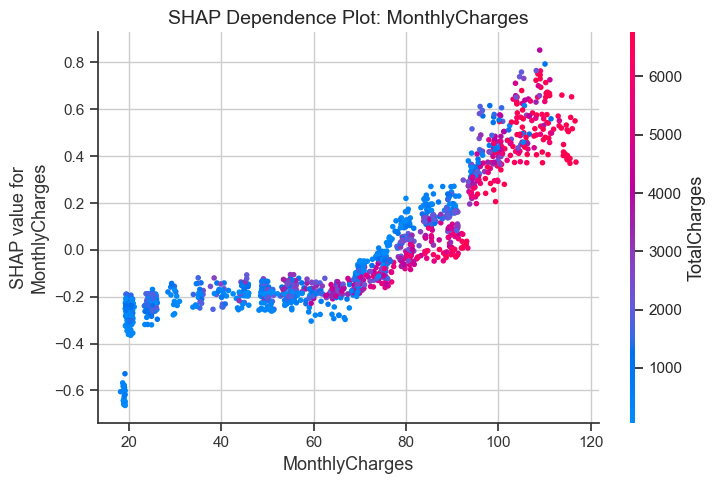

In [11]:
# 3. Dependence plot (зависимость от конкретного признака)
# Берем топ-1 признак из важности
top_feature = importances.iloc[0]['Feature']
print(f"Топ-1 признак: {top_feature}")

plt.figure(figsize=(10, 6))
shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)
plt.title(f'SHAP Dependence Plot: {top_feature}', fontsize=14)
plt.tight_layout()
plt.show()

## Интерпретация через SHAP

Для глубокого понимания того, как модель принимает решения, мы построили два типа графиков SHAP: Waterfall (объяснение для одного клиента) и Dependence (глобальная зависимость от конкретного признака).

### 1. Waterfall Plot (Анализ одного клиента)
На графике показан клиент с очень высоким риском оттока (итоговое значение \(f(x) = 2.685\), что соответствует высокой вероятности ухода). Базовое среднее значение по всей выборке составляет \(E[f(X)] = -0.591\). 

Модель «толкают» в сторону оттока (красные блоки) следующие факторы:
1. **Contract = 0 (+0.92)**: Самый сильный драйвер. Скорее всего, это помесячный контракт (Month-to-month), который несет максимальный риск.
2. **tenure = 1 (+0.43)**: Клиент с нами всего 1 месяц. Новички — главная группа риска.
3. **MonthlyCharges = 95.1 (+0.32)**: Высокий ежемесячный чек.
4. **OnlineSecurity = 0 и TechSupport = 0 (+0.25 и +0.24)**: У клиента нет дополнительных услуг защиты и поддержки, что снижает его «привязанность» к компании.
5. **TotalCharges = 95.1 (+0.25)**: Так как стаж всего 1 месяц, общая сумма равна месячной плате.

*Вывод по клиенту:* Это классический портрет «новичка», который сразу подключил дорогой тариф, но не взял пакет дополнительных услуг и сидит на помесячной оплате. Его нужно срочно удерживать!

### 2. Dependence Plot (Зависимость от MonthlyCharges)
График показывает, как меняется вклад признака `MonthlyCharges` в предсказание модели в зависимости от его значения.
- Видна четкая ступенчатая зависимость: при чеке до ~70 единиц SHAP-значение отрицательное (клиент лоялен), а после 80 — резко уходит в плюс (клиент уходит). 
- **Цвет точек (TotalCharges):** Это интерактивный эффект. При высоких значениях `MonthlyCharges` (справа) синие и фиолетовые точки (низкий `TotalCharges`) имеют более высокое значение SHAP, чем красные (высокий `TotalCharges`). Это означает, что модель больше боится клиентов с высоким ежемесячным чеком, которые **недавно** пришли в компанию, чем тех, кто платит такие же деньги, но уже давно.

**Итоговый бизнес-инсайт:**
Анализ SHAP подтверждает, что для удержания клиентов нужно бить точно в цель: предлагать пакеты с `OnlineSecurity` и `TechSupport` клиентам на помесячной оплате в первые 6 месяцев их обслуживания, особенно если их ежемесячный чек превышает 80 долларов.

In [12]:
# Сохранение всех моделей и метаданных
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
joblib.dump(label_encoders, 'models/label_encoders.pkl')

with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Сбор метрик
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': float(study.best_value),
    'best_params': study.best_params,
    'train_times': {'rf': rf_time, 'xgb': xgb_time, 'lgbm': lgbm_time, 'cat': cat_time}
}

with open('models/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Все модели и метаданные успешно сохранены в папку models/")

✅ Все модели и метаданные успешно сохранены в папку models/


In [13]:
# Демонстрация загрузки лучшей модели из GitHub
import requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/shunanovke/ml-course-shunanov/main/module-3-churn"

print("Демонстрация: код загрузки модели из репозитория")

try:
    # Загрузка модели
    model_url = f"{BASE_URL}/models/best_model.pkl"
    best_lgbm_loaded = joblib.load(BytesIO(requests.get(model_url).content))
    
    # Загрузка признаков
    features_url = f"{BASE_URL}/models/feature_cols.json"
    feature_cols_loaded = requests.get(features_url).json()
    
    print("✅ Модель загружена из репозитория")
    print(f"✅ Загружено {len(feature_cols_loaded)} признаков")
    
    # Проверка на 3 клиентах
    y_pred_loaded = best_lgbm_loaded.predict(X_test.iloc[:3])
    y_pred_original = best_lgbm.predict(X_test.iloc[:3])
    
    print(f"\nЗагруженная модель: {y_pred_loaded}")
    print(f"Исходная модель:   {y_pred_original}")
    print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")
    
except Exception as e:
    print(f"⚠️ Ошибка при загрузке: {e}")
    print("Проверка локальной модели:")
    local_model = joblib.load('models/best_model.pkl')
    print("✅ Локальная модель успешно загружена.")

Демонстрация: код загрузки модели из репозитория
✅ Модель загружена из репозитория
✅ Загружено 23 признаков

Загруженная модель: [0 1 0]
Исходная модель:   [0 1 0]
Совпадают: True


## Выводы

### Блок 1: Что получилось
- **Достигнутая точность:** Все ансамблевые модели показали высокие результаты (ROC-AUC > 0.83). Базовая модель LightGBM дала ROC-AUC = 0.8379.
- **Лучшая модель:** После тюнинга гиперпараметров через Optuna, модель **LightGBM** улучшила свой результат до **ROC-AUC = 0.8473** (прирост почти +1%). При этом Optuna сильно упростила модель (`num_leaves` снизилось с 31 до 10), что защитило её от переобучения.
- **Сравнение baseline-моделей:** До тюнинга лучший ROC-AUC показал **Random Forest** (0.8403). Лучший Recall (способность находить уходящих клиентов) показал **CatBoost** (0.7594), а лучший F1-score — **LightGBM** (0.6236).
- **Скорость обучения:** Random Forest обучился быстрее всех (0.27 сек), что делает его отличным выбором для быстрого прототипирования.
- **Ключевые инсайты (SHAP):** Главные факторы оттока — это тип контракта (помесячная оплата), высокий ежемесячный чек (`MonthlyCharges`) и короткий стаж (`tenure`). Наличие услуг `OnlineSecurity` и `TechSupport` значительно снижает вероятность ухода.

### Блок 2: Какие были трудности
- **Дисбаланс классов:** Ушедших клиентов 26.5%, оставшихся — 73.5%. Без специальных мер модель просто предсказывала бы "останется" для всех. Пришлось использовать `class_weight='balanced'` и `scale_pos_weight`. Это сильно подняло Recall (мы находим уходящих), но снизило Precision (появились ложные срабатывания).
- **Грязные данные в TotalCharges:** В этом столбце числа были записаны как строки с пробелами вместо пропусков. Пришлось использовать `pd.to_numeric(errors='coerce')` и заполнять медианой.
- **Понимание SHAP:** Разбираться с тем, как SHAP-значения соотносятся с категориальными признаками (после LabelEncoder) было сложно, так как "высокое" значение признака не всегда означает "лучшее".
- **Время работы Optuna:** Поиск гиперпараметров занимает время. 30 испытаний (trials) пролетели быстро, но для более глубокой оптимизации требуются часы вычислений.

### Блок 3: Возможные улучшения
1. **Применить Stacking:** Объединить предсказания Random Forest, XGBoost, LightGBM и CatBoost в одну мета-модель. Это часто дает прирост ROC-AUC еще на 1-2%.
2. **Использовать SMOTE:** Применить синтетическую генерацию данных для миноритарного класса (ушедших клиентов) вместо использования весов классов.
3. **Калибровка вероятностей:** Применить `CalibratedClassifierCV`. Сейчас модель выдает вероятности, которые могут быть не совсем точными. Бизнесу важно понимать, что "вероятность 80%" означает именно 8 уходов из 10.
4. **Добавить взаимодействия признаков:** Создать новые фичи, например, `MonthlyCharges * Contract`, чтобы модель лучше улавливала комбинации "дорогой тариф + месячный контракт".
5. **Тюнинг CatBoost и Random Forest:** Запустить Optuna не только для LightGBM, но и для других моделей, возможно, они покажут лучший результат.

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.